# Sombra Amiga: previsão de dia de calor perigoso em São Paulo

**Global Solution 2026.2, FIAP, Inteligência Artificial & Machine Learning**

Integrantes: Glauco Heitor Gonçalves (RM 555978) e Pedro Henrique Junqueira (RM 556278)

**Pergunta de ML:** com os dados meteorológicos de hoje, conseguimos prever se **amanhã** a temperatura máxima em São Paulo vai chegar a **32 °C ou mais**?

A resposta alimenta o alerta da véspera do app Sombra Amiga, que avisa idosos e trabalhadores de rua antes do dia quente.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, fbeta_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from preparar_dados import carregar_horario, diario

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEMENTE = 42
LIMITE_C = 32
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

## 1. Problema e dados reais

| Item | Valor |
|---|---|
| Fonte | INMET, dados históricos de estações automáticas |
| Link | https://portal.inmet.gov.br/dadoshistoricos |
| Estação | A701, São Paulo, Mirante de Santana (zona norte) |
| Período | 01/01/2015 a 31/10/2026, uma leitura por hora |

Os detalhes de qualidade e formato estão em [dados/README.md](dados/README.md). O carregamento trata as mudanças de formato entre os anos e converte a hora de UTC para o horário local (UTC-3).

In [2]:
horario = carregar_horario(Path("dados/a701"))
print(f"{len(horario):,} leituras horárias de {horario['local'].min():%d/%m/%Y} a {horario['local'].max():%d/%m/%Y}")

cobertura = (horario.groupby(horario["local"].dt.year)[["temp_c", "umidade_pct", "pressao_mb", "chuva_mm"]]
             .apply(lambda g: g.notna().mean() * 100).round(1))
cobertura.index.name = "ano"
cobertura.columns = ["temperatura %", "umidade %", "pressão %", "chuva %"]
cobertura.loc[2015:]

103,728 leituras horárias de 31/12/2014 a 31/10/2026


,temperatura %,umidade %,pressão %,chuva %
ano,,,,
2015,100.0,100.0,100.0,100.0
2016,99.2,99.2,99.2,99.2
2017,99.2,99.2,99.2,99.2
2018,100.0,100.0,100.0,100.0
2019,100.0,100.0,100.0,100.0
2020,100.0,100.0,100.0,100.0
2021,100.0,100.0,100.0,100.0
2022,100.0,100.0,100.0,100.0
2023,97.6,97.6,97.6,92.6


A cobertura fica acima de 97% em todos os anos. Agora agregamos as horas em dias locais e descartamos os dias com menos de 20 horas de leitura.

4,293 dias válidos, 29 dias descartados ou ausentes


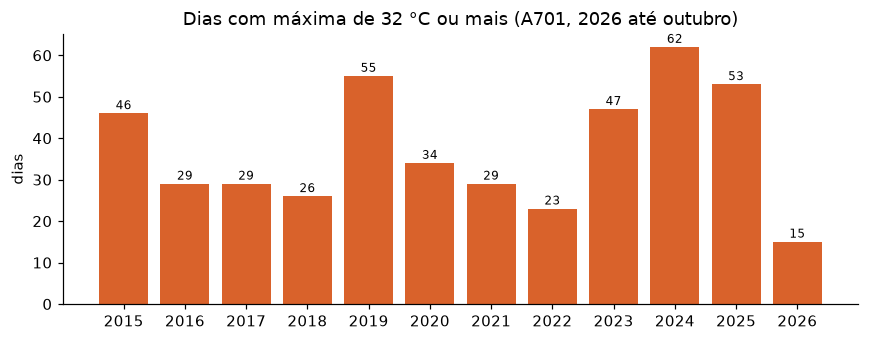

dia,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
dias_32,46.0,29.0,29.0,26.0,55.0,34.0,29.0,23.0,47.0,62.0,53.0,15.0
maxima,36.7,36.1,34.8,34.0,35.7,37.4,35.6,34.0,37.5,36.4,37.2,34.6


In [3]:
dias = diario(horario)
dias = dias[dias["horas"] >= 20].asfreq("D")
validos = dias["tmax"].notna()
print(f"{validos.sum():,} dias válidos, {(~validos).sum()} dias descartados ou ausentes")

por_ano = dias.loc[validos].groupby(dias.loc[validos].index.year)["tmax"].agg(
    dias_32=lambda s: (s >= LIMITE_C).sum(), maxima="max")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(por_ano.index.astype(str), por_ano["dias_32"], color="#d9622b")
ax.set_title(f"Dias com máxima de {LIMITE_C} °C ou mais (A701, 2026 até outubro)")
ax.set_ylabel("dias")
for x, v in zip(por_ano.index.astype(str), por_ano["dias_32"]):
    ax.text(x, v + 1, str(v), ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURAS / "dias_quentes_por_ano.png")
plt.show()
por_ano.T

## 2. Variável alvo e variáveis de entrada

**Alvo:** `calor_amanha = 1` quando a máxima do dia seguinte é de 32 °C ou mais. O limite é critério da equipe, escolhido porque coincide com o início da faixa "alto" do índice de calor usado na API.

**Entradas:** só informações disponíveis na noite de hoje, para não haver vazamento do futuro:

- Medidas do dia: máxima, mínima, média, umidade média e mínima, chuva, pressão, vento, radiação e índice de calor máximo
- Memória recente: máxima de ontem e anteontem, médias de 3 e 7 dias, variação da pressão
- Época do ano: seno e cosseno do dia do ano, para dezembro ficar perto de janeiro

In [4]:
def montar_base(d: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    x = d[["tmax", "tmin", "tmed", "umid_med", "umid_min", "chuva", "pressao", "vento", "radiacao", "ic_max"]].copy()
    x["tmax_ontem"] = d["tmax"].shift(1)
    x["tmax_anteontem"] = d["tmax"].shift(2)
    x["tmax_media_3d"] = d["tmax"].rolling(3).mean()
    x["tmax_media_7d"] = d["tmax"].rolling(7).mean()
    x["var_pressao"] = d["pressao"].diff()
    dia_ano = d.index.dayofyear
    x["epoca_sen"] = np.sin(2 * np.pi * dia_ano / 365.25)
    x["epoca_cos"] = np.cos(2 * np.pi * dia_ano / 365.25)

    amanha = d["tmax"].shift(-1)
    y = (amanha >= LIMITE_C).astype(float).where(amanha.notna())

    completos = x.notna().all(axis=1) & y.notna()
    return x[completos], y[completos].astype(int).rename("calor_amanha")


X, y = montar_base(dias)
print(f"{len(X):,} exemplos, {X.shape[1]} variáveis, {y.mean():.1%} de dias quentes no total")
X.head(3)

4,179 exemplos, 17 variáveis, 10.5% de dias quentes no total


,tmax,tmin,tmed,umid_med,umid_min,chuva,pressao,vento,radiacao,ic_max,tmax_ontem,tmax_anteontem,tmax_media_3d,tmax_media_7d,var_pressao,epoca_sen,epoca_cos
dia,,,,,,,,,,,,,,,,,
2015-01-07,33.6,18.7,24.008,67.292,31.0,47.0,926.900,1.546,23898.5,31.189,30.4,28.4,30.800,31.029,-1.546,0.120,0.993
2015-01-08,33.3,19.5,24.817,63.750,36.0,4.4,926.792,1.275,28844.1,31.509,33.6,30.4,32.433,31.143,-0.108,0.137,0.991
2015-01-09,33.6,21.7,27.833,55.042,30.0,0.0,925.988,1.262,29004.2,32.170,33.3,33.6,33.500,31.171,-0.804,0.154,0.988


## 3. Divisão treino e teste

A divisão é **temporal**: o treino usa 2015 a 2023 e o teste usa 2024 até outubro de 2026. Uma divisão aleatória misturaria dias vizinhos, que são muito parecidos, entre treino e teste. Isso inflaria o resultado e não representaria o uso real, em que o modelo prevê um futuro que nunca viu.

O conjunto de teste só é usado uma vez, na avaliação final.

In [5]:
eh_treino = X.index.year <= 2023
X_treino, y_treino = X[eh_treino], y[eh_treino]
X_teste, y_teste = X[~eh_treino], y[~eh_treino]

pd.DataFrame({
    "período": [f"{X_treino.index.min():%m/%Y} a {X_treino.index.max():%m/%Y}", f"{X_teste.index.min():%m/%Y} a {X_teste.index.max():%m/%Y}"],
    "exemplos": [len(X_treino), len(X_teste)],
    "dias quentes": [y_treino.sum(), y_teste.sum()],
    "% dias quentes": [f"{y_treino.mean():.1%}", f"{y_teste.mean():.1%}"],
}, index=["treino", "teste"])

,período,exemplos,dias quentes,% dias quentes
treino,01/2015 a 12/2023,3181,310,9.7%
teste,01/2024 a 10/2026,998,128,12.8%


## 4. Modelo escolhido

Usamos **Random Forest** (`RandomForestClassifier`) pelos motivos abaixo:

- Captura relações não lineares e combinações de variáveis, como "calor alto e umidade baixa", sem precisar criá-las à mão.
- Funciona bem com poucos milhares de exemplos e não exige normalizar as variáveis.
- Mostra a importância de cada variável, o que ajuda a explicar o modelo.
- Aceita `class_weight="balanced"`, importante porque só cerca de 10% dos dias são quentes.

Para saber se o modelo agrega valor, ele é comparado a duas referências simples:

1. **Persistência:** "amanhã será como hoje", ou seja, prevê calor se hoje já passou de 32 °C.
2. **Regressão logística só com a máxima de hoje:** um modelo linear com uma única variável.

## 5. Treino com diferentes hiperparâmetros

Testamos **24 combinações de 3 hiperparâmetros**:

| Hiperparâmetro | Valores | Efeito |
|---|---|---|
| `n_estimators` | 200, 400 | número de árvores |
| `max_depth` | 4, 8, 12, sem limite | profundidade máxima de cada árvore |
| `min_samples_leaf` | 1, 5, 20 | mínimo de exemplos em cada folha |

A validação cruzada usa `TimeSeriesSplit` com 5 dobras, **somente no treino**: cada dobra treina com o passado e valida no período seguinte. A métrica de escolha é a **precisão média (PR-AUC)**, adequada quando a classe positiva é rara.

In [6]:
grade = {
    "n_estimators": [200, 400],
    "max_depth": [4, 8, 12, None],
    "min_samples_leaf": [1, 5, 20],
}
validacao = TimeSeriesSplit(n_splits=5)
busca = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=SEMENTE, n_jobs=-1),
    grade,
    cv=validacao,
    scoring={"pr_auc": "average_precision", "f1": "f1"},
    refit="pr_auc",
    return_train_score=True,
    n_jobs=1,
)
busca.fit(X_treino, y_treino)

resultados = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    "n_estimators": resultados["param_n_estimators"],
    "max_depth": resultados["param_max_depth"].astype(object).where(resultados["param_max_depth"].notna(), "sem limite"),
    "min_samples_leaf": resultados["param_min_samples_leaf"],
    "PR-AUC treino": resultados["mean_train_pr_auc"],
    "PR-AUC validação": resultados["mean_test_pr_auc"],
    "desvio validação": resultados["std_test_pr_auc"],
    "F1 validação": resultados["mean_test_f1"],
}).sort_values("PR-AUC validação", ascending=False).reset_index(drop=True)
tabela["diferença"] = tabela["PR-AUC treino"] - tabela["PR-AUC validação"]
print("Melhor combinação:", busca.best_params_)
tabela

Melhor combinação: {'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 200}


,n_estimators,max_depth,min_samples_leaf,PR-AUC treino,PR-AUC validação,desvio validação,F1 validação,diferença
0,200,12,20,0.758,0.570,0.056,0.502,0.188
1,200,sem limite,20,0.758,0.570,0.056,0.502,0.188
2,200,8,20,0.757,0.569,0.056,0.505,0.189
3,400,8,20,0.759,0.562,0.059,0.504,0.197
4,400,sem limite,20,0.760,0.561,0.060,0.503,0.199
5,400,12,20,0.760,0.561,0.060,0.503,0.199
6,200,4,20,0.720,0.554,0.062,0.488,0.166
7,400,4,20,0.720,0.552,0.063,0.490,0.168
8,200,12,5,0.958,0.546,0.072,0.548,0.411
9,200,sem limite,5,0.959,0.543,0.071,0.550,0.416


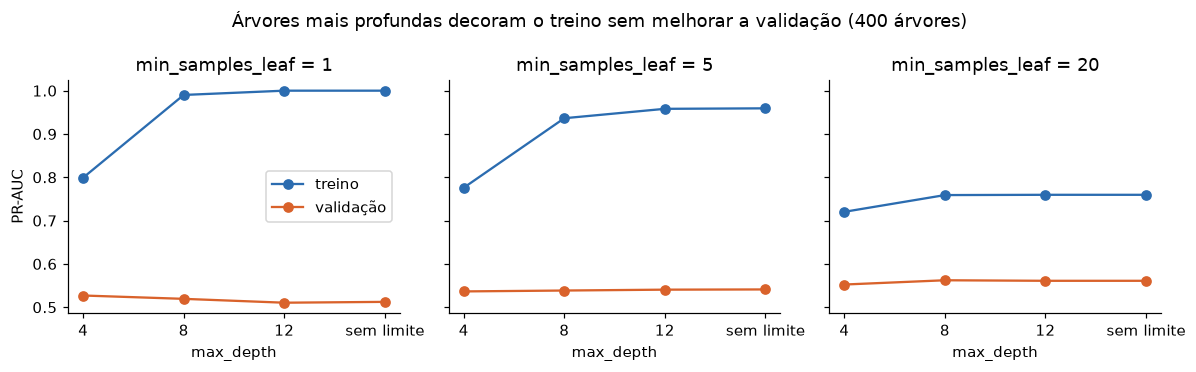

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for eixo, folha in zip(eixos, grade["min_samples_leaf"]):
    parte = tabela[(tabela["min_samples_leaf"] == folha) & (tabela["n_estimators"] == 400)]
    ordem = ["4", "8", "12", "sem limite"]
    parte = parte.set_index(parte["max_depth"].astype(str)).loc[ordem]
    eixo.plot(ordem, parte["PR-AUC treino"], marker="o", label="treino", color="#2b6cb0")
    eixo.plot(ordem, parte["PR-AUC validação"], marker="o", label="validação", color="#d9622b")
    eixo.set_title(f"min_samples_leaf = {folha}")
    eixo.set_xlabel("max_depth")
eixos[0].set_ylabel("PR-AUC")
eixos[0].legend()
fig.suptitle("Árvores mais profundas decoram o treino sem melhorar a validação (400 árvores)")
fig.tight_layout()
fig.savefig(FIGURAS / "overfitting_hiperparametros.png")
plt.show()

### Limiar de decisão

O modelo devolve uma probabilidade, e o corte padrão de 0,5 não é necessariamente o melhor. Para o cidadão, **deixar de avisar um dia perigoso é pior do que dar um alarme falso**. Por isso, escolhemos o limiar que maximiza o **F2**, uma métrica que valoriza mais o recall do que a precisão.

O limiar é escolhido com as previsões de validação das próprias dobras do treino, sem usar o teste.

In [8]:
melhores = busca.best_params_
prob_validacao, real_validacao = [], []
for idx_treino, idx_validacao in validacao.split(X_treino):
    modelo_dobra = RandomForestClassifier(class_weight="balanced", random_state=SEMENTE, n_jobs=-1, **melhores)
    modelo_dobra.fit(X_treino.iloc[idx_treino], y_treino.iloc[idx_treino])
    prob_validacao.append(modelo_dobra.predict_proba(X_treino.iloc[idx_validacao])[:, 1])
    real_validacao.append(y_treino.iloc[idx_validacao].to_numpy())
prob_validacao = np.concatenate(prob_validacao)
real_validacao = np.concatenate(real_validacao)

limiares = np.round(np.arange(0.10, 0.91, 0.05), 2)
f2_por_limiar = pd.Series([fbeta_score(real_validacao, prob_validacao >= t, beta=2) for t in limiares], index=limiares)
LIMIAR = float(f2_por_limiar.idxmax())
print(f"Limiar escolhido: {LIMIAR:.2f} (F2 de validação = {f2_por_limiar.max():.3f})")

troca = pd.DataFrame([
    {"limiar": t,
     "precisão": precision_score(real_validacao, prob_validacao >= t, zero_division=0),
     "recall": recall_score(real_validacao, prob_validacao >= t),
     "alertas a cada 100 dias": 100 * (prob_validacao >= t).mean()}
    for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
]).set_index("limiar")
troca

Limiar escolhido: 0.50 (F2 de validação = 0.652)


,precisão,recall,alertas a cada 100 dias
limiar,,,
0.3,0.260,0.940,34.453
0.4,0.302,0.881,27.774
0.5,0.358,0.821,21.849
0.6,0.431,0.738,16.302
0.7,0.503,0.623,11.774
0.8,0.573,0.421,6.981


## 6. Resultados em treino e teste

O modelo final usa a melhor combinação, retreinada com todo o período de treino. As métricas de treino e teste aparecem lado a lado.

In [9]:
modelo = busca.best_estimator_
prob_treino = modelo.predict_proba(X_treino)[:, 1]
prob_teste = modelo.predict_proba(X_teste)[:, 1]


def metricas(real, prob=None, previsto=None):
    previsto = (prob >= LIMIAR).astype(int) if previsto is None else previsto
    linha = {
        "precisão": precision_score(real, previsto, zero_division=0),
        "recall": recall_score(real, previsto),
        "F1": f1_score(real, previsto),
        "F2": fbeta_score(real, previsto, beta=2),
    }
    if prob is not None:
        linha["PR-AUC"] = average_precision_score(real, prob)
        linha["ROC-AUC"] = roc_auc_score(real, prob)
    return linha


logistica = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
logistica.fit(X_treino[["tmax"]], y_treino)
prob_logistica = logistica.predict_proba(X_teste[["tmax"]])[:, 1]

comparacao = pd.DataFrame({
    "Random Forest, treino": metricas(y_treino, prob_treino),
    "Random Forest, teste": metricas(y_teste, prob_teste),
    "Persistência, teste": metricas(y_teste, previsto=(X_teste["tmax"] >= LIMITE_C).astype(int)),
    "Logística só tmax, teste": metricas(y_teste, previsto=(prob_logistica >= 0.5).astype(int), prob=prob_logistica),
}).T
comparacao

,precisão,recall,F1,F2,PR-AUC,ROC-AUC
"Random Forest, treino",0.411,0.955,0.575,0.755,0.743,0.963
"Random Forest, teste",0.419,0.844,0.560,0.701,0.595,0.915
"Persistência, teste",0.579,0.570,0.575,0.572,NaN,NaN
"Logística só tmax, teste",0.361,0.859,0.508,0.673,0.556,0.895


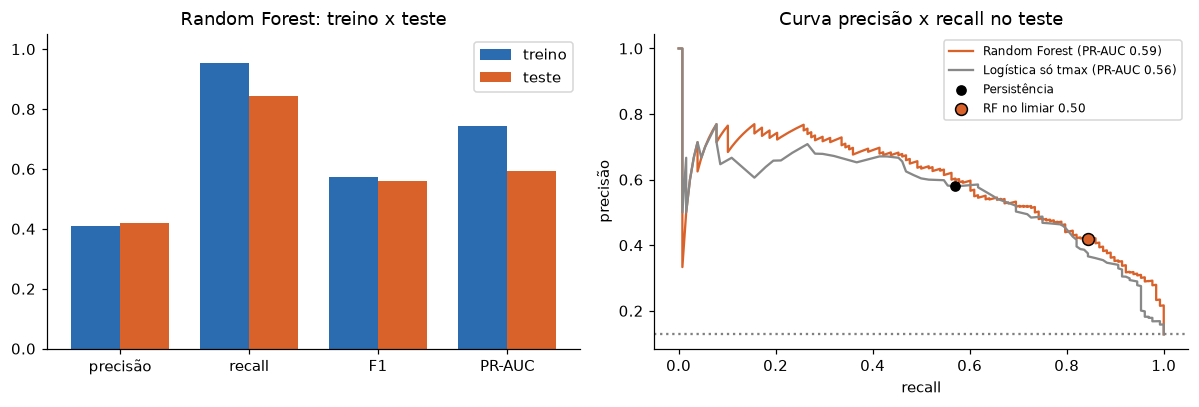

In [10]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))

nomes = ["precisão", "recall", "F1", "PR-AUC"]
largura = 0.38
posicoes = np.arange(len(nomes))
a.bar(posicoes - largura / 2, comparacao.loc["Random Forest, treino", nomes], largura, label="treino", color="#2b6cb0")
a.bar(posicoes + largura / 2, comparacao.loc["Random Forest, teste", nomes], largura, label="teste", color="#d9622b")
a.set_xticks(posicoes, nomes)
a.set_ylim(0, 1.05)
a.set_title("Random Forest: treino x teste")
a.legend()

for nome, prob, cor in [("Random Forest", prob_teste, "#d9622b"), ("Logística só tmax", prob_logistica, "#888888")]:
    precisao, recall, _ = precision_recall_curve(y_teste, prob)
    b.plot(recall, precisao, label=f"{nome} (PR-AUC {average_precision_score(y_teste, prob):.2f})", color=cor)
persist = comparacao.loc["Persistência, teste"]
b.scatter(persist["recall"], persist["precisão"], color="black", zorder=3, label="Persistência")
rf = comparacao.loc["Random Forest, teste"]
b.scatter(rf["recall"], rf["precisão"], color="#d9622b", edgecolor="black", s=60, zorder=3, label=f"RF no limiar {LIMIAR:.2f}")
b.axhline(y_teste.mean(), ls=":", color="gray")
b.set_xlabel("recall")
b.set_ylabel("precisão")
b.set_title("Curva precisão x recall no teste")
b.legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURAS / "treino_teste_e_curva_pr.png")
plt.show()

In [11]:
previsto_teste = (prob_teste >= LIMIAR).astype(int)
matriz = pd.DataFrame(confusion_matrix(y_teste, previsto_teste),
                      index=["real: dia normal", "real: dia quente"],
                      columns=["previsto: normal", "previsto: quente"])

virada = (X_teste["tmax"] < LIMITE_C) & (y_teste == 1)
print(f"Dias quentes que vieram depois de um dia ameno (viradas): {virada.sum()}")
print(f"  Random Forest acertou: {previsto_teste[virada.to_numpy()].sum()}")
print("  Persistência acertou: 0, porque ela só repete o dia anterior")
matriz

Dias quentes que vieram depois de um dia ameno (viradas): 55
  Random Forest acertou: 35
  Persistência acertou: 0, porque ela só repete o dia anterior


,previsto: normal,previsto: quente
real: dia normal,720,150
real: dia quente,20,108


In [12]:
por_ano_teste = pd.DataFrame([
    {"ano": ano, "dias": int(m.sum()), "dias quentes": int(y_teste[m].sum()), **metricas(y_teste[m], prob_teste[m])}
    for ano in sorted(set(X_teste.index.year))
    for m in [X_teste.index.year == ano]
]).set_index("ano")
por_ano_teste[["dias", "dias quentes", "precisão", "recall", "F1", "PR-AUC"]]

,dias,dias quentes,precisão,recall,F1,PR-AUC
ano,,,,,,
2024,358,62,0.426,0.790,0.554,0.555
2025,357,51,0.495,0.902,0.639,0.719
2026,283,15,0.260,0.867,0.400,0.445


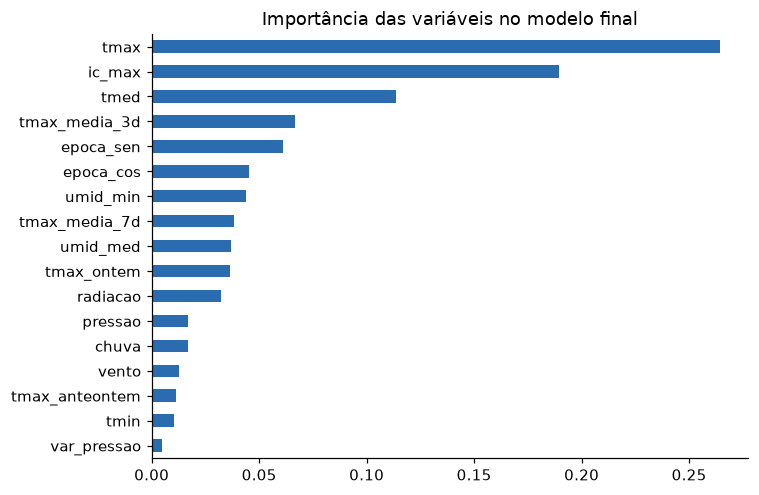

In [13]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
importancias.plot.barh(ax=ax, color="#2b6cb0")
ax.set_title("Importância das variáveis no modelo final")
fig.tight_layout()
fig.savefig(FIGURAS / "importancia_variaveis.png")
plt.show()

## 7. Discussão

### Overfitting

O gráfico da seção 5 mostra o problema com clareza. Com `min_samples_leaf = 1`, as árvores decoram o treino: a PR-AUC de treino chega a 1,00, enquanto a de validação fica entre 0,51 e 0,53. Exigir pelo menos 20 exemplos por folha derruba a PR-AUC de treino para cerca de 0,76 e **melhora** a validação para 0,57. Por isso essa foi a combinação escolhida.

O modelo final ainda tem uma diferença entre treino (PR-AUC 0,74) e teste (0,60), mas bem menor do que nas versões sem restrição. A precisão é praticamente igual nos dois conjuntos (0,41 e 0,42). Quem cai é o recall, de 0,96 para 0,84.

### Comparação honesta com as referências

- O Random Forest **avisa muito mais dias quentes** do que a persistência: recall de 0,84 contra 0,57.
- Em compensação, erra mais: **150 alarmes falsos** em 998 dias de teste, e só 42% dos alertas se confirmam.
- No **F1**, que pesa precisão e recall igualmente, o modelo **empata** com a persistência (0,56 contra 0,58).
- Na curva precisão x recall, o ponto da persistência fica quase em cima da curva do modelo. No mesmo nível de recall, os dois têm precisão parecida.
- A logística, que usa só a máxima de hoje, fica pouco abaixo do Random Forest (PR-AUC 0,56 contra 0,59). A maior parte da informação está na própria temperatura de hoje.

O ganho real do modelo está em dois pontos:

1. **Ajustar o equilíbrio:** com a persistência, não há o que regular. Com o modelo, o limiar troca alarmes falsos por dias perdidos, como mostra a tabela da seção 5.
2. **Prever viradas:** nos 55 dias quentes que vieram depois de um dia ameno, o modelo avisou 35. A persistência, por definição, não avisa nenhum.

### Mudança entre os períodos

O teste é mais quente do que o treino: 12,8% de dias quentes contra 9,7%, com 62 dias em 2024 e 53 em 2025. A PR-AUC do teste (0,60) sai um pouco acima da validação (0,57), mas isso **não** significa que o modelo melhorou. Com mais dias quentes, a PR-AUC tende a subir naturalmente.

Em 2026, os dados vão só até outubro e o verão ainda não chegou: houve apenas 15 dias quentes, e a precisão cai para 0,26.

### Limitações

- Usamos uma única estação, o Mirante de Santana, para representar a cidade inteira. A Brasilândia pode ser mais quente.
- O modelo não usa previsão numérica do tempo, que é o que os serviços meteorológicos usam. Ele complementa os avisos oficiais e não os substitui.
- O limite de 32 °C é critério da equipe, sem validação clínica.

## 8. O que isso significa para o cidadão

- **De cada 100 dias de calor perigoso**, o modelo avisaria na véspera cerca de **84**. A regra "amanhã será como hoje" avisaria 57.
- **O calor que chega de surpresa também é avisado:** em 35 de 55 dias quentes que vieram depois de um dia ameno, o aviso chegou na véspera.
- **O custo são os alarmes falsos:** cerca de 6 em cada 10 alertas não se confirmam. Para um idoso, um alarme falso custa pouco, como beber mais água ou evitar o sol do meio-dia. Já um dia perigoso sem aviso pode terminar em internação.
- **Alarmes demais fazem as pessoas pararem de prestar atenção.** Por isso, no Sombra Amiga, a previsão da véspera é um aviso de preparação. No próprio dia, os sensores dos pontos de hidratação confirmam o nível real de risco.

**Na solução:** a previsão entra pela rota `POST /api/alertas/previsao` da API, como alerta de origem "Previsao", e o app mostra esse aviso na noite anterior.